In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import sys
import random

sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [2]:
import warnings

warnings.filterwarnings("ignore")

In [3]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

In [4]:
sc.set_figure_params(figsize=(5, 5))

read in mapqc results:

In [5]:
results_healthy = mapqc.load(
    "../remappings/Thienpont_2018_10Xv2_kl1_sample_as_batch/mapqc_results_healthy_all_samples.pkl"
)
results_disease = mapqc.load(
    "../remappings/Thienpont_2018_10Xv2_kl1_sample_as_batch/mapqc_results_disease_all_samples.pkl"
)

read in embedding with mapped query:

In [6]:
adata_emb = sc.read_h5ad(
    "../remappings/Thienpont_2018_10Xv2_kl1_sample_as_batch/combined_embedding_klweight_1.h5ad"
)

shuffle row order emb for plotting:

In [7]:
shuffled_idc = adata_emb.obs.index.tolist()
random.shuffle(shuffled_idc)
adata_emb = adata_emb[shuffled_idc, :].copy()

add mapQC results to embedding with both healthy and diseased:

In [8]:
for stat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    adata_emb.obs[stat] = np.nan
    healthy_idc = [
        idx for idx in adata_emb.obs.index if idx in results_healthy.adata.obs.index
    ]
    adata_emb.obs.loc[healthy_idc, stat] = results_healthy.adata.obs.loc[
        healthy_idc, stat
    ]
    disease_idc = [
        idx for idx in adata_emb.obs.index if idx in results_disease.adata.obs.index
    ]
    adata_emb.obs.loc[disease_idc, stat] = results_disease.adata.obs.loc[
        disease_idc, stat
    ]

read in raw reference data in backed mode:

In [51]:
adata_full = sc.read_h5ad(
    "../../../../../../workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/d10_1101_2022_03_10_483747/HLCA_v1.1_full.h5ad",
    backed="r",
)

In [10]:
adata_emb

AnnData object with n_obs × n_vars = 678519 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'organism_ontology_term_id', 'sex_ontology_term_id', "3'_or_5'", 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'core_or_extension', 'dataset', 'fresh_or_frozen', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'original_ann_level_1', 'original_ann_level_2', 'original_ann_level_3', 'original_ann_level_4', 'original_ann_level_5', 'original_ann_nonharmonized', 'reannotation_type', 'sample', 'scanvi_label', 'sequencing_platform', 'smoking_status', 'study', 'subject_type', 'tissue_coarse_unharmonized', 'tis

### Visualize mapQC results on controls:

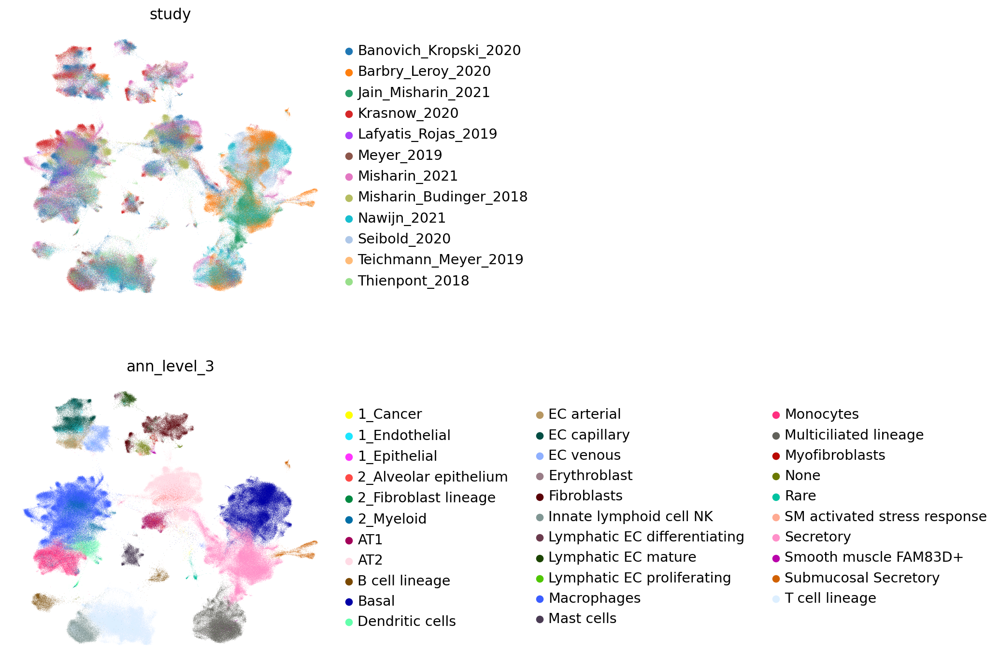

In [11]:
sc.pl.umap(
    results_healthy.adata, color=["study", "ann_level_3"], frameon=False, ncols=1
)

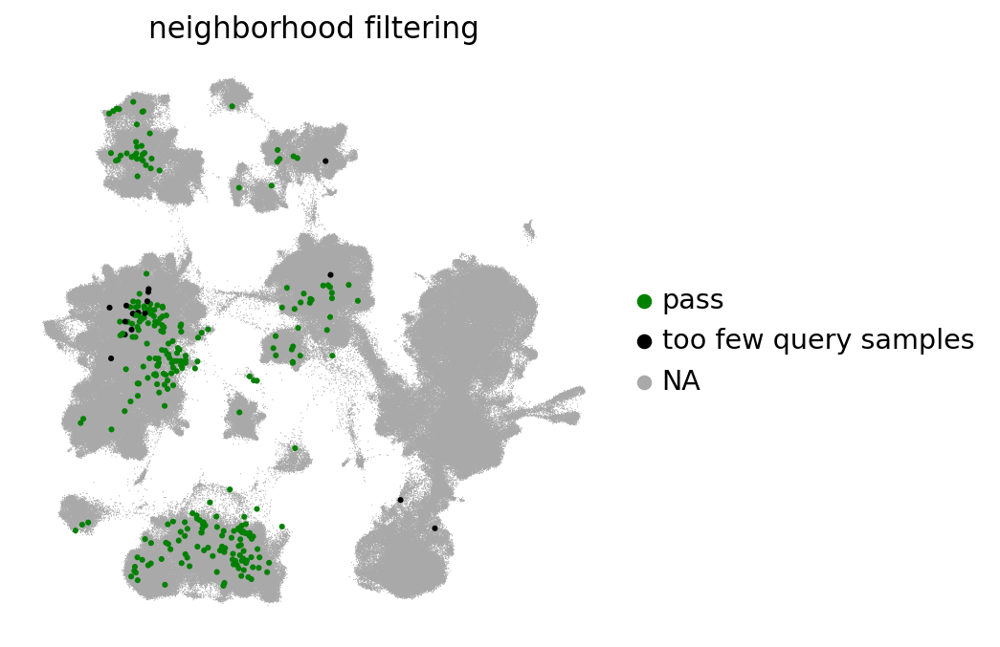

In [12]:
plotting.plot_umap_filtering_info(results_healthy)

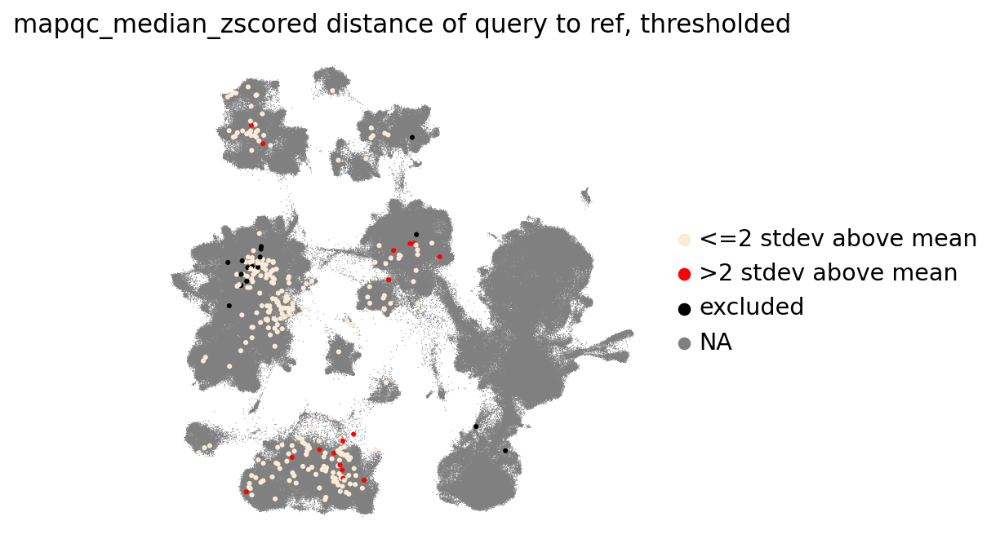

In [13]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy, color_by="median_zscore>2")

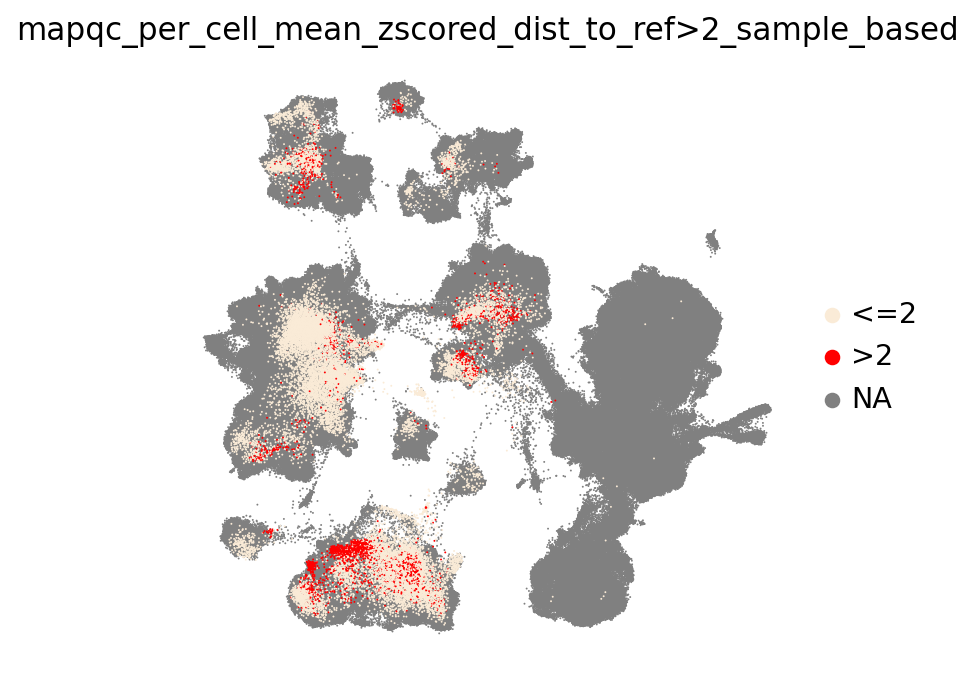

In [14]:
plotting.plot_umap_cell_level_results(results_healthy, size=3)

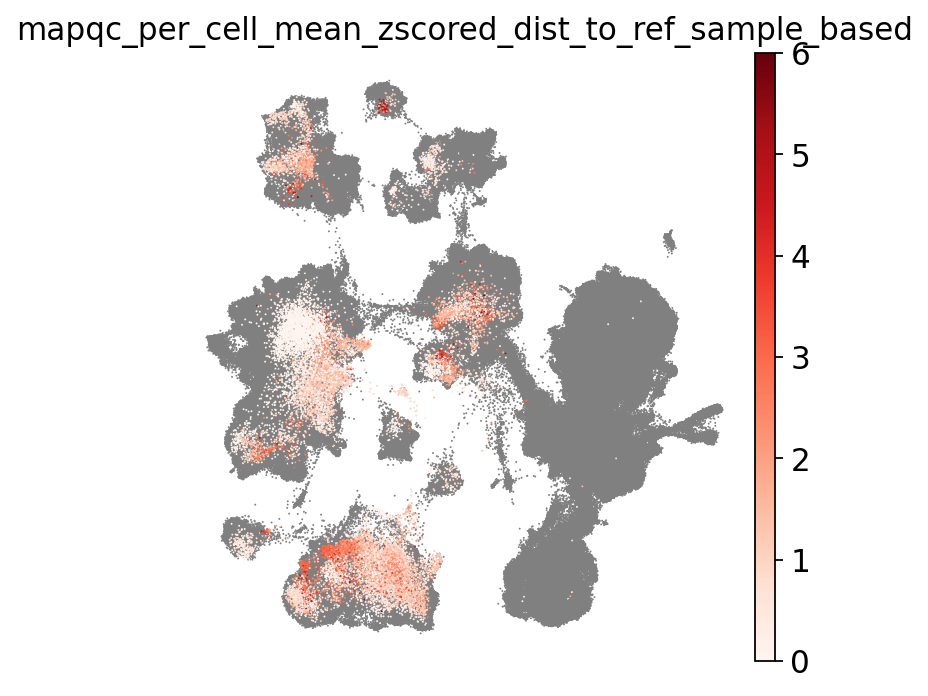

In [15]:
plotting.plot_umap_cell_level_results(
    results_healthy, size=3, color_by="zscore", vmin=0, vmax=6
)

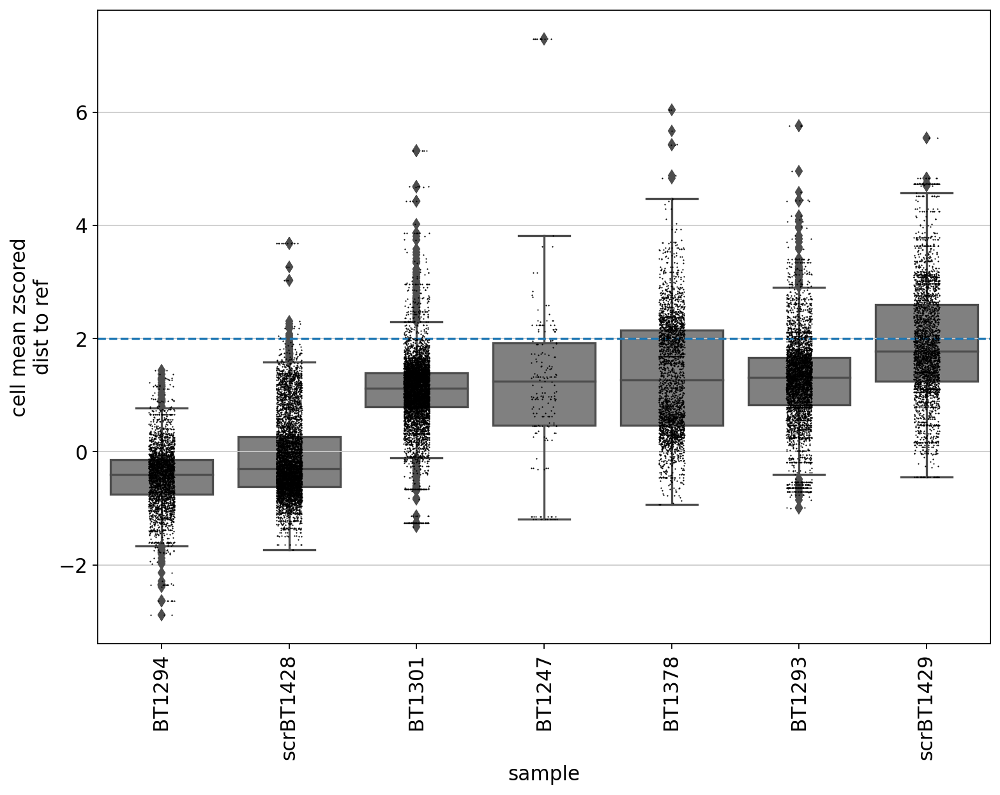

In [16]:
plotting.plot_sample_distances_to_reference_cell_level(results_healthy)

### Visualize results disease:

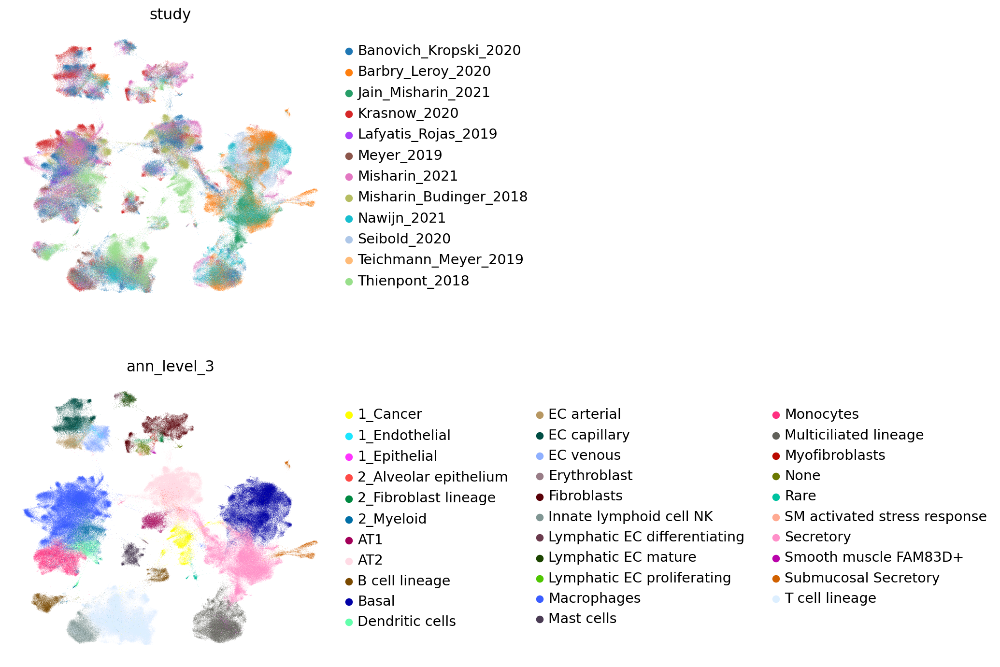

In [17]:
sc.pl.umap(
    results_disease.adata, color=["study", "ann_level_3"], frameon=False, ncols=1
)

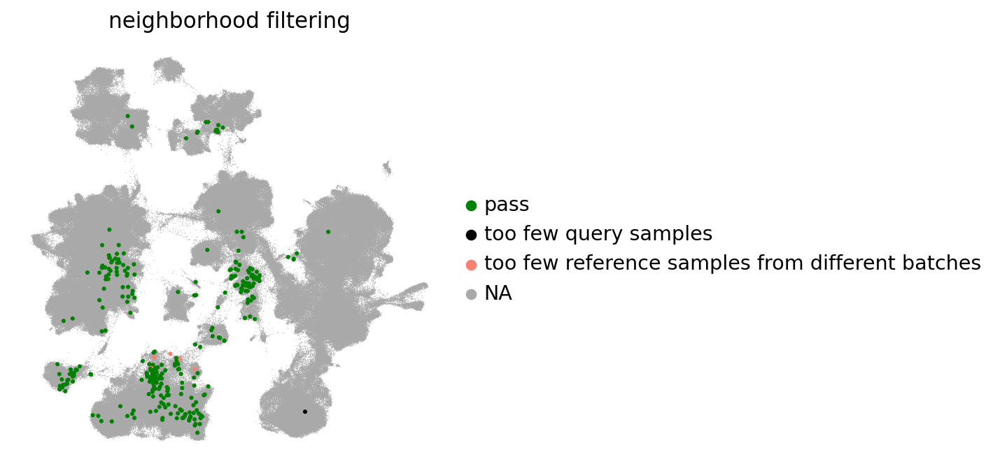

In [18]:
plotting.plot_umap_filtering_info(results_disease)

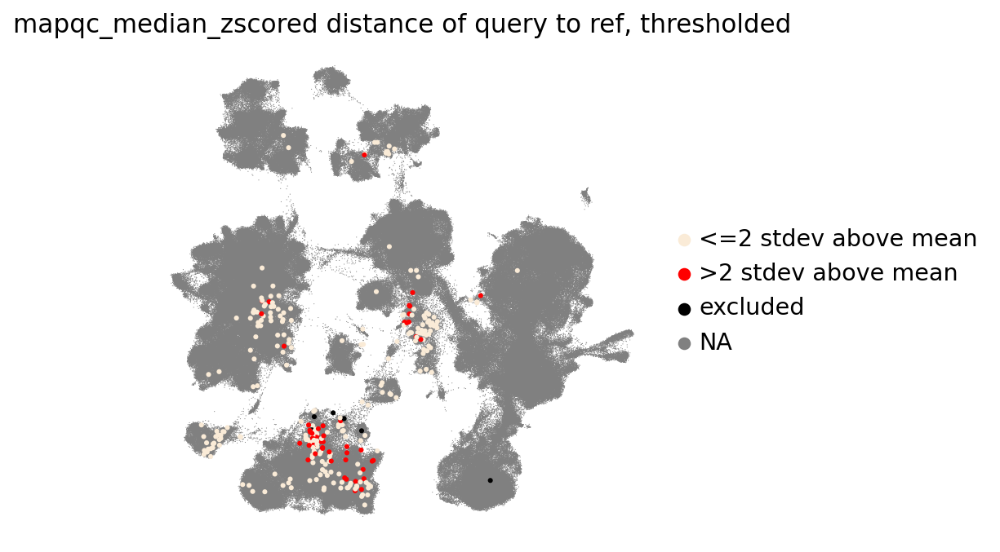

In [19]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease, color_by="median_zscore>2")

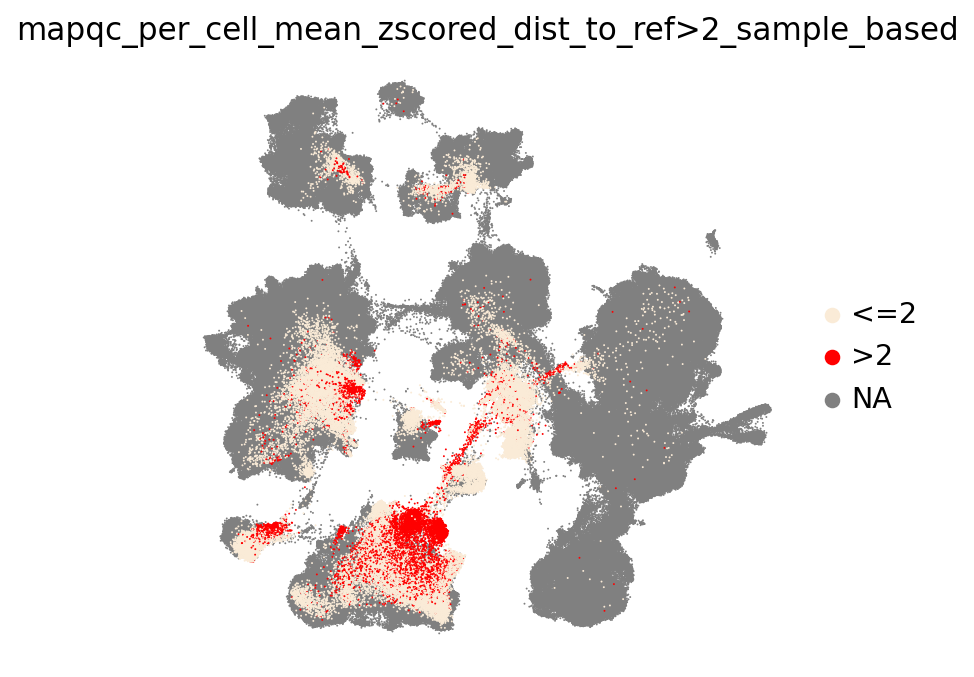

In [20]:
plotting.plot_umap_cell_level_results(results_disease, size=3)

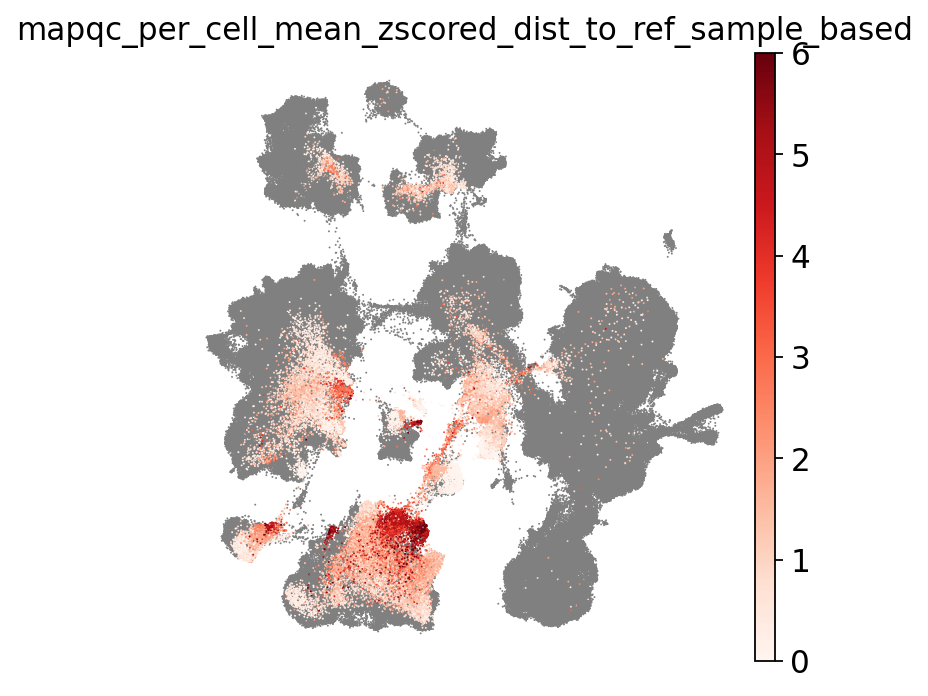

In [21]:
plotting.plot_umap_cell_level_results(
    results_disease, size=3, color_by="zscore", vmin=0, vmax=6
)

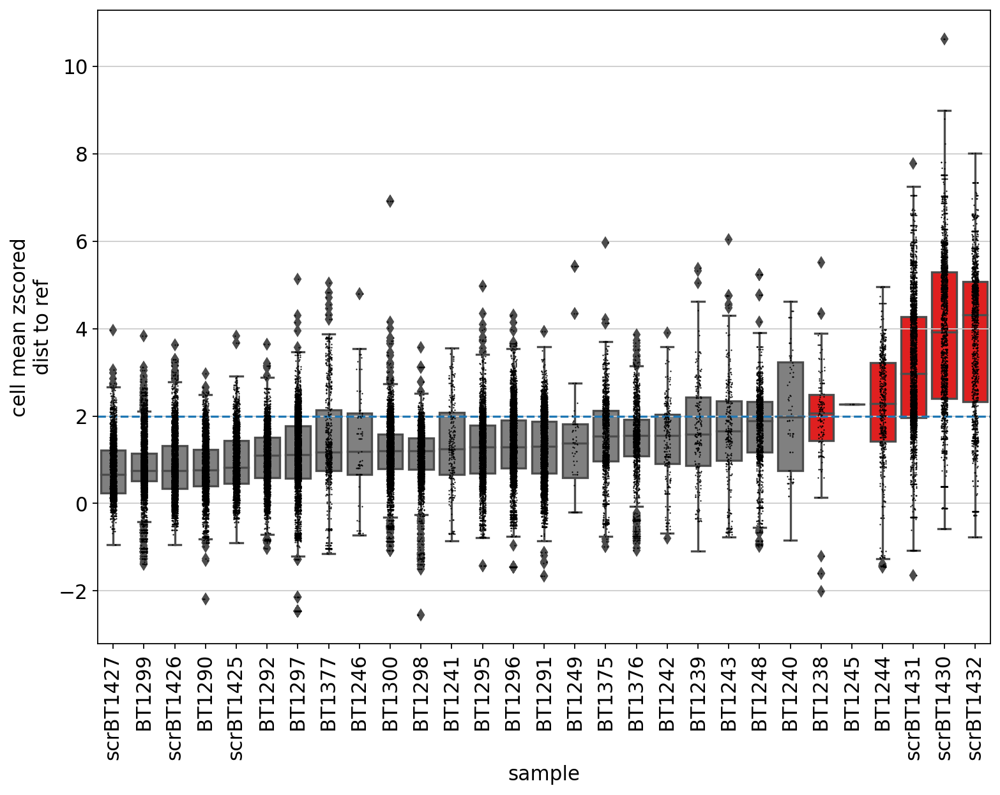

In [22]:
plotting.plot_sample_distances_to_reference_cell_level(results_disease)

### Analyze non-mixing NK/T cells in healthy:

In [23]:
# palette_ref_q = {
#     "Reference": "lightgrey",
#     "Query control": "dodgerblue",
#     "Query Asherman Syndrome": "darkblue",
# }

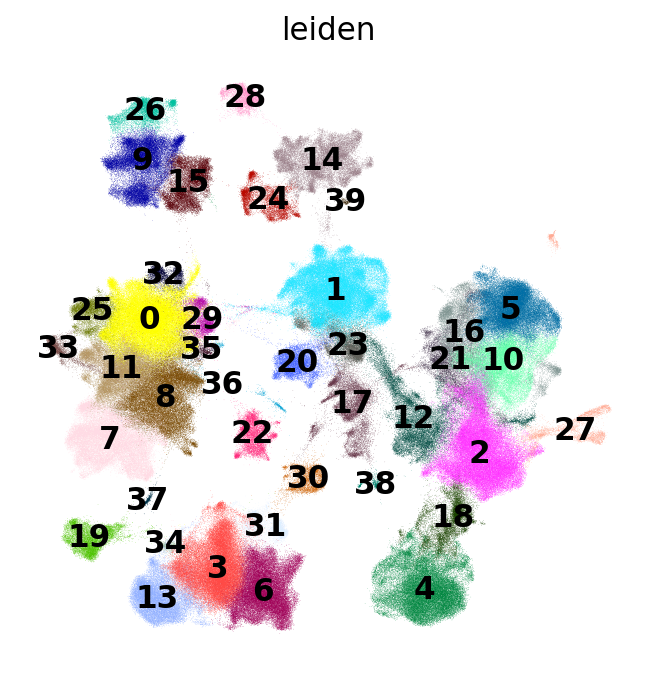

In [27]:
sc.pl.umap(adata_emb, color=["leiden"], frameon=False, legend_loc="on data")

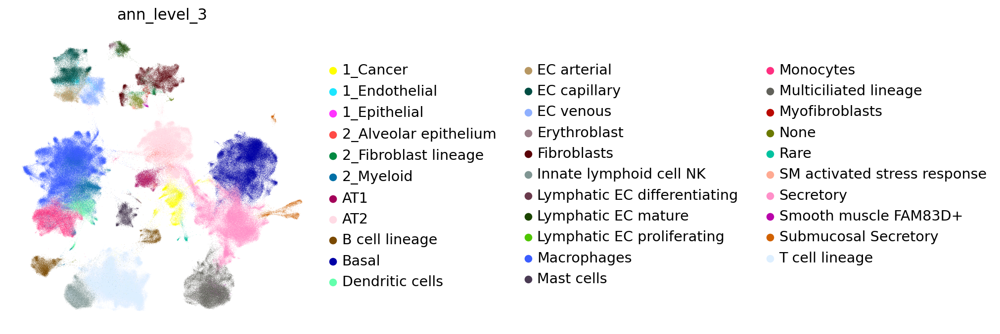

In [28]:
sc.pl.umap(adata_emb, color=["ann_level_3"], frameon=False)

Select based on leiden cluster, but for now use annotations until I have clustering ready:

In [29]:
NK_T_clusters = [3, 6, 13, 31, 34]

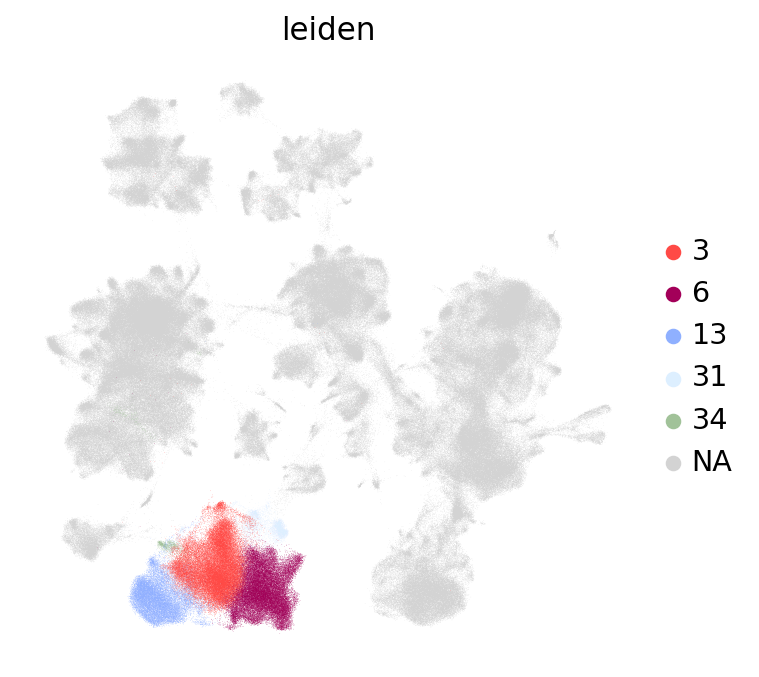

In [30]:
sc.pl.umap(adata_emb, color=["leiden"], frameon=False, groups=NK_T_clusters)

In [31]:
adata_T_ILC_emb = adata_emb[adata_emb.obs.leiden.isin(NK_T_clusters), :].copy()

In [32]:
sc.pp.neighbors(adata_T_ILC_emb, n_neighbors=30)

In [33]:
sc.tl.umap(adata_T_ILC_emb)

In [34]:
sc.tl.leiden(adata_T_ILC_emb, key_added="leiden_T_ILC", resolution=1)

add category specifying sample only for query:

In [35]:
adata_T_ILC_emb.obs["query_sample"] = np.nan
adata_T_ILC_emb.obs.loc[
    adata_T_ILC_emb.obs.core_or_extension == "extension", "query_sample"
] = adata_T_ILC_emb.obs.loc[
    adata_T_ILC_emb.obs.core_or_extension == "extension", "sample"
]

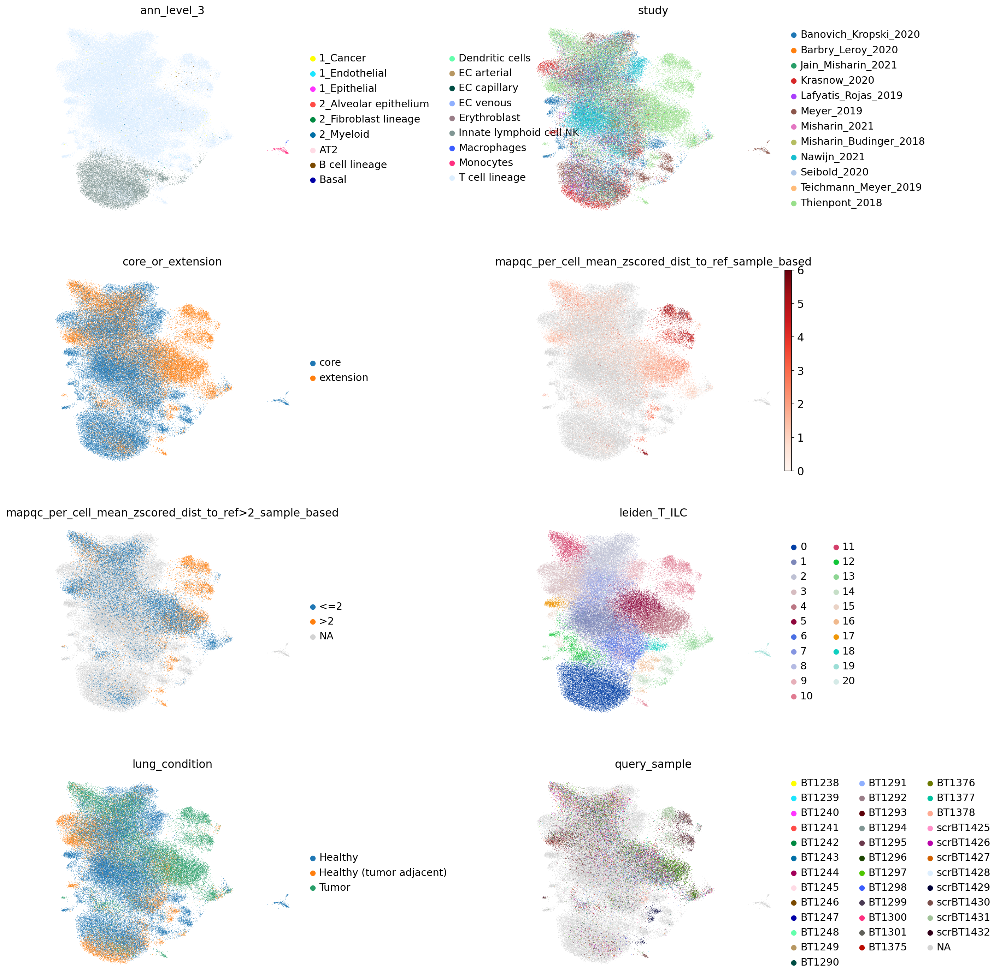

In [38]:
sc.pl.umap(
    adata_T_ILC_emb,
    color=[
        "ann_level_3",
        "study",
        "core_or_extension",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
        "leiden_T_ILC",
        "lung_condition",
        "query_sample",
    ],
    frameon=False,
    ncols=2,
    wspace=0.7,
    cmap="Reds",
    vmin=0,
    vmax=6,
)

#### Include counts

remove lambrechts suffix from adata_full barcodes (this was added for the Thienpont study), so that barcodes of embedding and adata full correspond:

In [73]:
new_idc = [idc.split("_lambrechts")[0] for idc in adata_full.obs.index]
adata_full.obs.index = new_idc

In [ ]:
adata_T_ILC = adata_full[adata_T_ILC_emb.obs.index, :].to_memory()

In [ ]:
adata_T_ILC.obsm["X_umap"] = adata_T_ILC_emb.obsm["X_umap"]
for obs_cat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    "leiden",
    "leiden_T_ILC",
]:
    adata_T_ILC.obs[obs_cat] = adata_T_ILC_emb.obs.loc[adata_T_ILC.obs.index, obs_cat]

In [ ]:
print('test')

In [ ]:
print('test')

In [ ]:
adata_epi.uns["log1p"]["base"] = None

In [ ]:
sc.pl.umap(adata_epi, color="leiden", groups=[23])

In [ ]:
sc.pl.umap(adata_epi, color="leiden_epi", groups=["16", "17"])

In [ ]:
# sc.tl.rank_genes_groups(adata_epi, groupby="leiden_epi", groups=["16"], reference="17")

In [ ]:
# sc.pl.rank_genes_groups(adata_epi)

In [ ]:
# sc.pl.umap(adata_epi, color=["PDGFRA"])

In [ ]:
sc.tl.rank_genes_groups(adata_epi, groupby="leiden_epi", groups=[12, 16])

In [ ]:
sc.pl.rank_genes_groups(adata_epi)

In [ ]:
cluster_16_markers_used_during_mapping = [
    gene
    for gene in sc.get.rank_genes_groups_df(adata_epi, group="16").names[:100]
    if adata_full.var.loc[gene, "highly_variable"]
]

In [ ]:
cluster_16_neg_markers_used_during_mapping = [
    gene
    for gene in sc.get.rank_genes_groups_df(adata_epi, group="16").names[-100:]
    if adata_full.var.loc[gene, "highly_variable"]
]

In [ ]:
cluster_16_markers = [
    "ATP5F1E",
    "ATP5MD",
    "ATP5ME",
    "ATP5IF1",
    "FTH1",
    "UCA1",
    "TPD52L1",
    "SCGB2A1",
    "HIST1H4C",
]

In [ ]:
sc.pl.umap(adata_epi, color=["leiden_epi"] + cluster_16_markers, wspace=0.45)

In [ ]:
sc.pl.umap(
    adata_epi,
    color=["leiden_epi"] + cluster_16_neg_markers_used_during_mapping[-25:],
    wspace=0.45,
)

In [ ]:
cluster_12_markers = ["COL3A1", "COL1A1", "SPARC", "LGALS1", "PTGDS"]

In [ ]:
sc.pl.umap(adata_epi, color=["leiden_epi"] + cluster_12_markers, wspace=0.45)

from figure 1c AS paper:

In [ ]:
paper_markers_AS_epi = ["SLPI", "HSPA1A", "SOCS3", "SNHG9", "MMP7"]

In [ ]:
sc.pl.umap(
    adata_epi,
    color=["leiden_epi", "reference_or_query", "Group"] + paper_markers_AS_epi,
    wspace=0.45,
)

In [ ]:
adata_epi.obs["ref_or_query_condition"] = adata_epi.obs.reference_or_query.tolist()
adata_epi.obs.loc[
    adata_epi.obs.Group == "AS", "ref_or_query_condition"
] = "query_disease"
adata_epi.obs.loc[
    adata_epi.obs.Group == "WOI Control", "ref_or_query_condition"
] = "query_control"
adata_epi.obs["leiden_epi_source"] = [
    f"{cl} ({cond})"
    for cl, cond in zip(adata_epi.obs.leiden_epi, adata_epi.obs.ref_or_query_condition)
]
# clean up to remove groups that have fewer than min_n_cells:
leiden_epi_source_counts = adata_epi.obs.leiden_epi_source.value_counts()
leiden_epi_source_mapping = {
    group: (group if leiden_epi_source_counts[group] > 50 else "Other")
    for group in leiden_epi_source_counts.index
}
adata_epi.obs.leiden_epi_source = adata_epi.obs.leiden_epi_source.map(
    leiden_epi_source_mapping
)

In [ ]:
sc.pl.dotplot(
    adata_epi,
    var_names={
        "cluster 12": cluster_12_markers,
        "cluster 16": cluster_16_markers_used_during_mapping[:10],
        "cluster 16 neg": cluster_16_neg_markers_used_during_mapping[-10:],
        "AS epithelium paper markers": paper_markers_AS_epi,
    },
    groupby="leiden_epi_source",
    standard_scale="var",
)

Notes:
- cluster 12 (seemingly disease specific cluster) has genes (COL3A1, COL1A1, SPARC) that are also expressed in query control cells from that same cluster. Question to answer: does that mean these are not disease-specific cells, but rather batch-related artefacts?
- cluster 16: query-specific genes again, this cluster does not include (>100) reference cells. check if these were used during mapping? Seems batch-effect related. This would mean that mapQC correctly flags these cells as not well mapped based on the control.

In [ ]:
adata_full.obsm["X_umap"] = adata_emb[adata_full.obs.index, :].obsm["X_umap"]

In [ ]:
sc.pl.umap(adata_full, color=["EPCAM", "VIM", "IGF1"])

In [ ]:
sc.pl.umap(adata_full, color="celltype_query")

In [ ]:
sc.pl.umap(adata_full, color="celltype_query", groups=["Epi-PDGFRA"])

In [ ]:
sc.pl.umap(adata_full, color=paper_markers_AS_epi)

In [ ]:
sc.pl.umap(adata_full, color=paper_markers_AS_epi, sort_order=False)

In [ ]:
adata_full.obs["leiden"] = adata_emb.obs.loc[adata_full.obs.index, "leiden"]

In [ ]:
adata_full.uns["log1p"]["base"] = None

In [ ]:
adata_full.obs.leiden[0] == 7

In [ ]:
adata_full = adata_full.to_memory()

In [ ]:
sc.tl.rank_genes_groups(adata_full, groupby="leiden", reference=0)  # also try 22

In [ ]:
sc.pl.rank_genes_groups(adata_full, groups=["12"])

In [ ]:
sc.pl.umap(
    adata_full,
    color=["SCGB2A1", "CLDN4", "SAT1", "CLDN3", "PERP", "WFDC2", "ELF3", "CD9"],
)

looks like cluster 12 are doublets right? 

In [ ]:
cluster_12_markers

In [ ]:
paper_markers_AS_epi

In [ ]:
doublet_markers = {
    "epithelial": ["SCGB2A1", "CLDN3", "WFDC2", "ELF3", "CD9"],
    "stromal": ["COL3A1", "COL1A1", "SPARC", "PTGDS"],
    "AS epithelium markers": paper_markers_AS_epi,
}

In [ ]:
adata_full.obs["leiden_AS_epithelium"] = adata_full.obs.leiden.tolist()
adata_full.obs.loc[
    (
        (adata_full.obs.celltype_query == "AS-Epithelium")
        & (adata_full.obs.leiden == 24)
    ),
    "leiden_AS_epithelium",
] = "24 (AS Epithelium)"

In [ ]:
sc.pl.dotplot(
    adata_full,
    groupby="leiden_AS_epithelium",
    var_names=doublet_markers,
    standard_scale="var",
)

In [ ]:
sc.pl.dotplot(
    adata_full,
    groupby="celltype_query",
    var_names=doublet_markers,
    standard_scale="var",
)

In [ ]:
sc.pl.dotplot(
    adata_full, groupby="leiden", var_names=paper_markers_AS_epi, standard_scale="var"
)

In [ ]:
sc.pl.umap(adata_full, color=cluster_12_markers + cluster_16_markers + ["celltype"])

### Analyze non-mixing stromal cells:

make sure that healthy non-mixing don't display the same pattern!

In [ ]:
adata_EC_emb.obs["reference_or_query_subset"] = adata_emb.obs.loc[
    adata_EC_emb.obs.index, "reference_or_query_subset"
]

In [ ]:
adata_EC_emb = adata_emb[adata_emb.obs.leiden == 6, :].copy()

add mapqc results from both healthy and diseased:

In [ ]:
# for stat in [
#     "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
#     "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
# ]:
#     adata_EC_emb.obs[stat] = np.nan
#     healthy_idc = [
#         idx for idx in adata_EC_emb.obs.index if idx in results_healthy.adata.obs.index
#     ]
#     adata_EC_emb.obs.loc[healthy_idc, stat] = results_healthy.adata.obs.loc[
#         healthy_idc, stat
#     ]
#     disease_idc = [
#         idx for idx in adata_EC_emb.obs.index if idx in results_disease.adata.obs.index
#     ]
#     adata_EC_emb.obs.loc[disease_idc, stat] = results_disease.adata.obs.loc[
#         disease_idc, stat
#     ]

In [ ]:
sc.pp.neighbors(adata_EC_emb, n_neighbors=30)

In [ ]:
sc.tl.umap(adata_EC_emb)

In [ ]:
sc.tl.leiden(adata_EC_emb, resolution=0.4, key_added="leiden_EC")

create some further joint metadata:

In [ ]:
adata_EC_emb.obs["leiden_EC_group"] = [
    f"{cl} ({gr})" for cl, gr in zip(adata_EC_emb.obs.leiden_EC, adata_EC_emb.obs.Group)
]
adata_EC_emb.obs["leiden_EC_group_sample"] = [
    f"{cl_gr} ({s})"
    for cl_gr, s in zip(adata_EC_emb.obs.leiden_EC_group, adata_EC_emb.obs["sample"])
]

In [ ]:
sc.pl.umap(adata_EC_emb, color="leiden_EC")

In [ ]:
adata_EC = adata_full[adata_EC_emb.obs.index, :].to_memory()

In [ ]:
adata_EC.obsm["X_umap"] = adata_EC_emb.obsm["X_umap"]
for obs_cat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
    "leiden",
    "leiden_EC",
    "leiden_EC_group",
    "leiden_EC_group_sample",
    "reference_or_query_subset",
]:
    adata_EC.obs[obs_cat] = adata_EC_emb.obs.loc[adata_EC.obs.index, obs_cat]

In [ ]:
sc.pl.umap(
    adata_EC,
    color=[
        "Group",
        "dataset",
        "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
        "celltype",
        "celltype_query",
        "leiden_EC",
    ],
    wspace=0.5,
)

In [ ]:
sc.tl.rank_genes_groups(adata_EC, groupby="leiden_EC")

subset to genes used during mapping:

In [ ]:
deg_non_mixing_EC_cl = sc.get.rank_genes_groups_df(adata_EC, group="4")
deg_non_mixing_EC_cl_genes_used_for_mapping = [
    gene
    for gene in deg_non_mixing_EC_cl.names
    if adata_full.var.loc[gene, "highly_variable"]
]

In [ ]:
sc.pl.umap(adata_EC, color=deg_non_mixing_EC_cl_genes_used_for_mapping[:20])

In [ ]:
pd.crosstab(adata_EC.obs.leiden_EC, adata_EC.obs.reference_or_query_subset).plot(
    kind="bar", stacked=True, color=palette_ref_q
)

In [ ]:
sc.pl.dotplot(
    adata_EC,
    groupby="leiden_EC",
    var_names=deg_non_mixing_EC_cl_genes_used_for_mapping[:14],
    standard_scale="var",
)

In [ ]:
# sc.pl.umap(adata_full, color=["PLCG2", "reference_or_query"])

In [ ]:
adata_full.obs["reference_or_query_subset"] = adata_emb.obs.loc[
    adata_full.obs.index, "reference_or_query_subset"
]
adata_full.obs["leiden_group"] = [
    f"{cl} ({gr})"
    for cl, gr in zip(adata_full.obs.leiden, adata_full.obs.reference_or_query_subset)
]
adata_full.obs["group_leiden"] = [
    f"{cl} ({gr})"
    for cl, gr in zip(adata_full.obs.reference_or_query_subset, adata_full.obs.leiden)
]

In [ ]:
[
    gene
    for gene in deg_non_mixing_EC_cl_genes_used_for_mapping[:20]
    if not gene.startswith("MT-")
]

In [ ]:
batch_genes = ["NEAT1", "MTRNR2L12", "PLCG2", "MTRNR2L8", "COL4A1", "FOSB"]

In [ ]:
sc.pl.dotplot(
    adata_full[adata_full.obs.leiden.isin(range(10)), :],
    groupby="group_leiden",
    var_names=batch_genes,
    standard_scale="var",
)